# 1. Imports

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
PROJECT = "/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project" # Adjust this path if your repository is cloned elsewhere

In [4]:
import sys
import os

# Assuming 'PROJECT' is defined as the base path to your cloned repository
repo_src_path = os.path.join(PROJECT, '00_Reference/Original_Github_Repo/src')
if repo_src_path not in sys.path:
    sys.path.insert(0, repo_src_path)

print(f"Added '{repo_src_path}' to sys.path.")

Added '/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/00_Reference/Original_Github_Repo/src' to sys.path.


In [6]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 52.8 MB/s eta 0:00:00


In [7]:
from data_preparation import *
from preprocessing import *

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader

from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import random

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    precision_score,
    recall_score,
    top_k_accuracy_score,
)

import torchmetrics
from torchmetrics.classification import MulticlassConfusionMatrix

## 1.1 SEED SET

In [8]:
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)

# 2. Data

In [9]:
# path = '/BMIS_EMG_DATA/data/mat_data'
path = os.path.join(PROJECT, '01_Data/EMG/raw')
subject_number = 1
end_subject = 33
fs = 200
number_gestures = 4
record_time = 5
train_repetition = [1, 2, 3, 4, 5, 6]
test_repetition = [3, 5]
gesture = [1, 2, 3, 4, 5, 6, 7]
selected_gesture = [1, 2, 3, 4]
num_gesture = len(gesture)

notch_freq=60.0
low_cut=10.0
high_cut=99.0
order=5

window_time=200
overlap=60
no_channel=8

batch_size = 32

In [10]:
emg_prep = EMGDataPreparation(base_path=path, fs=fs, rec_time=record_time)
data, labels, _, _ = emg_prep.load_multiple_subject(start_subject=subject_number, end_subject=end_subject, num_gesture=num_gesture, train_repetition=train_repetition, test_repetition=test_repetition, selected_gesture=selected_gesture)
data.shape, labels.shape

((8, 792000), (792000,))

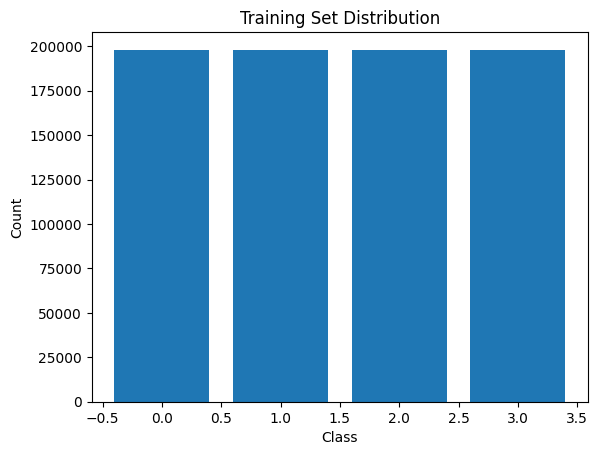

In [11]:
np.unique(labels, return_counts=True)
counts_train = np.unique(labels, return_counts=True)



plt.bar(counts_train[0], counts_train[1])
plt.title('Training Set Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

## 2.1. Data Preprocessing

In [12]:
preprocess = EMGPreprocessing(fs=fs, notch_freq=notch_freq, low_cut=low_cut, high_cut=high_cut, order=order)

# Notch filter
data = preprocess.remove_mains(data)

# Bandpass filter
data = preprocess.bandpass_filter(data)

# Windowing
data, labels = emg_prep.window_with_overlap(data, labels, window_time=window_time, overlap=overlap, no_channel=no_channel)
data = np.expand_dims(data, axis=1)

# data = scale_data_normalization(data)

In [13]:
# Shuffle the data
data, labels = shuffle_data(data, labels)
train_data, train_labels, test_data, test_labels = data_split(data, labels, train_ratio=80) # 80% train, 20% test
print(f'The training data shape is {train_data.shape}')
print(f'The testing data shape is {test_data.shape}')
print(f'The maximum value in the training data is {np.max(train_data)}')
print(f'The minimum value in the training data is {np.min(train_data)}')
print(f'The maximum value in the testing data is {np.max(test_data)}')
print(f'The minimum value in the testing data is {np.min(test_data)}')

The training data shape is (39598, 1, 8, 40)
The testing data shape is (9900, 1, 8, 40)
The maximum value in the training data is 229.63696847518887
The minimum value in the training data is -226.17683637503754
The maximum value in the testing data is 211.04744132249763
The minimum value in the testing data is -201.04365198803748


In [14]:
traindataset = EMGDataset(train_data, train_labels)
testdataset = EMGDataset(test_data, test_labels)

train_loader = DataLoader(traindataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(testdataset, batch_size=batch_size, shuffle=False)

# 3. EMGNet Architecture

In [15]:
class EMGNet(nn.Module):
    def __init__(self, out_gesture):
        super(EMGNet, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3)
        self.batchnorm1 = nn.BatchNorm2d(32)
        self.maxpool2 = nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2))
        self.dropout = nn.Dropout(0.5)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(1152, 256)
        self.fc2 = nn.Linear(256, out_gesture)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.batchnorm1(x)
        x = self.maxpool2(x)
        x = self.dropout(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.fc2(x)
        return x

In [16]:
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = EMGNet(out_gesture=number_gestures)
model = model.cuda()
model

EMGNet(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
  (batchnorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxpool2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=4, bias=True)
)

# 4. Training and Validation

In [17]:
epochs = 64
learning_rate =  1e-3
weight_decay = 1e-5
gamma = 0.8
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)

In [18]:
def train_loop(model, train_device, data, loss_fn, optimizer, scheduler):

    model.train()
    train_loss = 0
    correct = 0
    total = 0

    for X, y in data:

        X = X.float().to(train_device)
        y = y.long().to(train_device)

        optimizer.zero_grad()
        model = model.to(train_device)

        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        loss.backward()
        optimizer.step()
        #scheduler.step()
        total += y.size(0)
        correct += (y_pred.argmax(1) == y).sum().item()

    return train_loss / total, correct / total

In [19]:
def test_loop(model, train_device, data, loss_fn):
    model.eval()
    test_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in data:
            X = X.float().to(train_device)
            y = y.long().to(train_device)
            model = model.to(train_device)

            y_pred = model(X)
            loss = loss_fn(y_pred, y)

            test_loss += loss.item()
            _, predicted = torch.max(y_pred.data, 1)
            correct += (y == predicted).sum().item()
            #total += y.size(0)
            #correct += (y_pred.argmax(1) == y).sum().item()
    test_loss /= len(data.dataset)
    accuracy = correct / len(data.dataset)
    return test_loss, accuracy

In [20]:
print(f"Training on {device}")
train_accuracy_per_epoch = []
test_accuracy_per_epoch = []


for epoch in tqdm(range(epochs)):

    train_loss, train_acc = train_loop(model, device, train_loader, criterion, optimizer, scheduler)
    #test_loss, test_acc = test_loop(model, device, test_loader, criterion)


    train_accuracy_per_epoch.append(train_acc)
    #test_accuracy_per_epoch.append(test_acc)
    # save_dir = f"{save_path}/mcunet_pretrain_{epoch+1}.pth"
    # torch.save(model.state_dict(), save_dir)

AVG_TRAIN_ACC = np.mean(train_accuracy_per_epoch)
AVG_TEST_ACC = np.mean(test_accuracy_per_epoch)

print(f"Epoch {epoch+1}/{epochs}")
print(f"The Average Train accuracy: {AVG_TRAIN_ACC*100:.4f}%")
#print(f"The Average Test accuracy: {AVG_TEST_ACC*100:.4f}%")

# print(f'Training accuracy {train_acc*100:.4f}%')
# print(f'Test accuracy {test_acc*100:.4f}%')


Training on cuda


100%|██████████| 64/64 [04:32<00:00,  4.26s/it]

Epoch 64/64
The Average Train accuracy: 82.1057%



/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
# print(f'The CLER is {100 - AVG_TEST_ACC*100:.4f}%')

# Test Accuracy

In [21]:
test_loss, test_acc = test_loop(model, device, test_loader, criterion)
print(f'The CLER is {100 - test_acc*100:.4f}%')

The CLER is 12.5758%


In [ ]:
# base = ''
# save_dir = base + str(end_subject)+'.pth'
# torch.save(model.state_dict(), save_dir)

In [25]:
# --- Model Saving Section ---
import torch # Ensure torch is imported

model_save_dir = os.path.join(PROJECT, '05_Models/EMG')
os.makedirs(model_save_dir, exist_ok=True)

model_save_path = os.path.join(model_save_dir, 'emgnet_model.pth')

if 'model' in locals() and isinstance(model, torch.nn.Module):
    torch.save(model.state_dict(), model_save_path)
    print(f"Model saved successfully to: '{model_save_path}'")
else:
    print("Model object not found or not a torch.nn.Module, skipping model save.")
# --- End Model Saving Section ---

Model saved successfully to: '/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/05_Models/EMG/emgnet_model.pth'


# 5. Confusion Matrix

[[2353   17   75   30]
 [  59 2058  185  156]
 [  50   68 2347   64]
 [  66  314  161 1897]]


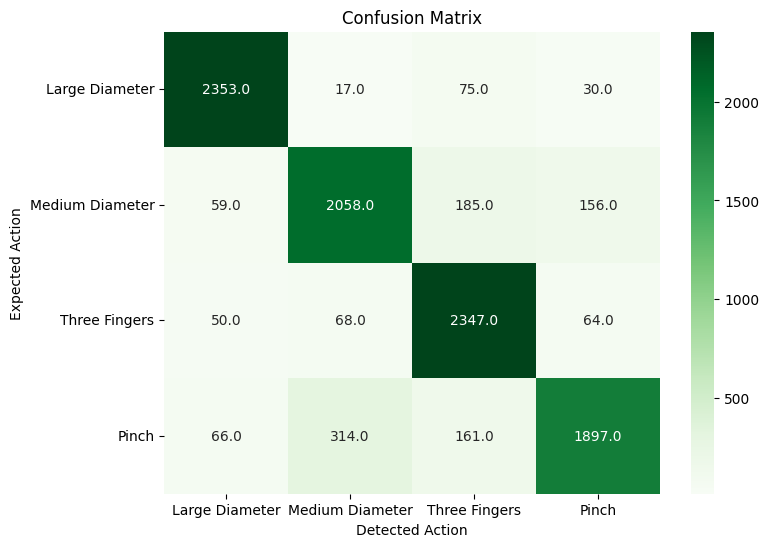

In [23]:
y_pred = model(torch.tensor(test_data).float().to(device)).argmax(1)
y_true = torch.tensor(test_labels).to(device)
# Initialize confusion matrix metric and move it to the same device as the model
conf_matrix_metric = MulticlassConfusionMatrix(num_classes=number_gestures).to(device)
# Compute confusion matrix
conf_matrix = conf_matrix_metric(y_pred, y_true)
# Move confusion matrix to CPU for visualization
conf_matrix = conf_matrix.cpu().numpy()
print(conf_matrix)

actions = ["Large Diameter", "Medium Diameter", "Three Fingers", "Pinch"]

# Create heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt=".1f", cmap="Greens", xticklabels=actions, yticklabels=actions)

# Labels and title
plt.xlabel("Detected Action")
plt.ylabel("Expected Action")
plt.title("Confusion Matrix")

# Show the plot
plt.show()

# 6. Number of Parameters

In [24]:
number_of_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The number of parameters is {number_of_parameters}')

The number of parameters is 305828
